<a href="https://colab.research.google.com/github/renzaflorencia/Supermarket-Retail-Sales-Data-Analysis/blob/main/Supermarket_Retail_Sales_Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from pandas.core.common import random_state
from sklearn.linear_model import LinearRegression

data = pd.read_csv("annex1.csv")
data2 = pd.read_csv("annex2.csv")
data3 = pd.read_csv("annex3.csv")
data4 = pd.read_csv("annex4.csv")

#Preparation

In [3]:
data_gabungan = pd.merge(data, data2, on = "Item Code", how = 'left')
data_gabungan.head()

,Item Code,Item Name,Category Code,Category Name,Date,Time,Quantity Sold (kilo),Unit Selling Price (RMB/kg),Sale or Return,Discount (Yes/No)
0,102900005115168,Niushou Shengcai,1011010101,Flower/Leaf Vegetables,2020-10-30,10:02:13.748,0.743,5.0,sale,No
1,102900005115168,Niushou Shengcai,1011010101,Flower/Leaf Vegetables,2020-10-30,10:48:42.707,0.502,5.0,sale,No
2,102900005115168,Niushou Shengcai,1011010101,Flower/Leaf Vegetables,2020-10-30,11:10:13.023,0.301,5.0,sale,No
3,102900005115168,Niushou Shengcai,1011010101,Flower/Leaf Vegetables,2020-10-30,12:34:32.084,0.382,5.0,sale,No
4,102900005115168,Niushou Shengcai,1011010101,Flower/Leaf Vegetables,2020-10-30,13:33:59.748,0.261,5.0,sale,No


In [4]:
data_gabungan.describe()

,Item Code,Category Code,Quantity Sold (kilo),Unit Selling Price (RMB/kg)
count,8.785080e+05,8.785080e+05,878503.000000,878503.000000
mean,1.030313e+14,1.011010e+09,0.536112,8.917144
std,7.174348e+11,2.582928e+02,0.400087,6.311265
min,1.029000e+14,1.011010e+09,-9.082000,0.100000
25%,1.029000e+14,1.011010e+09,0.290000,4.900000
50%,1.029000e+14,1.011010e+09,0.435000,7.900000
75%,1.029000e+14,1.011011e+09,0.742000,10.800000
max,1.069740e+14,1.011011e+09,160.000000,119.900000


#data cleaning

In [9]:
#hapus/ pisahkan transaksi yang kuantitasnya  minus
df_clean = data_gabungan[data_gabungan['Quantity Sold (kilo)'] > 0].copy()

In [10]:
df_clean['Date'] = pd.to_datetime(df_clean['Date'])

#membuat kolom baru

In [12]:
df_clean['Total Revenue'] = (
    df_clean['Unit Selling Price (RMB/kg)'] * df_clean['Quantity Sold (kilo)']
)

df_clean

,Item Code,Item Name,Category Code,Category Name,Date,Time,Quantity Sold (kilo),Unit Selling Price (RMB/kg),Sale or Return,Discount (Yes/No),Total Revenue
0,102900005115168,Niushou Shengcai,1011010101,Flower/Leaf Vegetables,2020-10-30,10:02:13.748,0.743,5.0,sale,No,3.715
1,102900005115168,Niushou Shengcai,1011010101,Flower/Leaf Vegetables,2020-10-30,10:48:42.707,0.502,5.0,sale,No,2.510
2,102900005115168,Niushou Shengcai,1011010101,Flower/Leaf Vegetables,2020-10-30,11:10:13.023,0.301,5.0,sale,No,1.505
3,102900005115168,Niushou Shengcai,1011010101,Flower/Leaf Vegetables,2020-10-30,12:34:32.084,0.382,5.0,sale,No,1.910
4,102900005115168,Niushou Shengcai,1011010101,Flower/Leaf Vegetables,2020-10-30,13:33:59.748,0.261,5.0,sale,No,1.305
...,...,...,...,...,...,...,...,...,...,...,...
878503,106973990980123,Hfyg Haixian Mushroom (Bunch),1011010801,Edible Mushroom,2022-07-28,20:26:46.053,1.000,1.5,sale,Yes,1.500
878504,106973990980123,Hfyg Haixian Mushroom (Bunch),1011010801,Edible Mushroom,2022-07-28,20:47:51.842,1.000,2.5,sale,No,2.500
878505,106973990980123,Hfyg Haixian Mushroom (Bunch),1011010801,Edible Mushroom,2022-07-28,20:48:23.670,1.000,1.5,sale,Yes,1.500
878506,106973990980123,Hfyg Haixian Mushroom (Bunch),1011010801,Edible Mushroom,2022-07-29,18:42:16.217,1.000,2.5,sale,No,2.500


In [17]:
#ekstraksi waktu

df_clean['Month'] = df_clean['Date'].dt.month
df_clean['Day_of_Week'] = df_clean['Date'].dt.day_name()
df_clean['Hour'] = pd.to_datetime(
    df_clean['Time'], format= '%H:%M:%S', errors= 'coerce'
).dt.hour

df_clean.describe()

,Item Code,Category Code,Date,Quantity Sold (kilo),Unit Selling Price (RMB/kg),Total Revenue,Month,Hour
count,8.780420e+05,8.780420e+05,878042,878042.000000,878042.000000,878042.00000,878042.000000,132.000000
mean,1.030313e+14,1.011010e+09,2021-11-20 19:32:55.239453440,0.536735,8.917098,3.84039,6.573310,15.136364
min,1.029000e+14,1.011010e+09,2020-07-01 00:00:00,0.003000,0.100000,0.02010,1.000000,9.000000
25%,1.029000e+14,1.011010e+09,2021-02-06 00:00:00,0.290000,4.900000,2.21000,3.000000,11.750000
50%,1.029000e+14,1.011010e+09,2021-10-11 00:00:00,0.435000,7.900000,3.33400,7.000000,16.000000
75%,1.029000e+14,1.011011e+09,2022-09-10 00:00:00,0.742000,10.800000,4.79160,9.000000,18.000000
max,1.069740e+14,1.011011e+09,2023-06-30 00:00:00,160.000000,119.900000,944.00000,12.000000,22.000000
std,7.174241e+11,2.582905e+02,NaN,0.398989,6.311023,2.80449,3.440708,3.503047


#analysis dan visualisasi

In [19]:
top_categories=(
    df_clean.groupby('Category Name')['Total Revenue'].sum().sort_values(ascending=False)
)

top_categories.head(10)

,Total Revenue
Category Name,
Flower/Leaf Vegetables,1.079835e+06
Capsicum,7.545644e+05
Edible Mushroom,6.201102e+05
Cabbage,3.759808e+05
Aquatic Tuberous Vegetables,3.503061e+05
Solanum,1.912270e+05


/tmp/ipykernel_4348/3497088634.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data = top_items, x = 'Quantity Sold (kilo)', y='Item Name', palette='Blues_r')


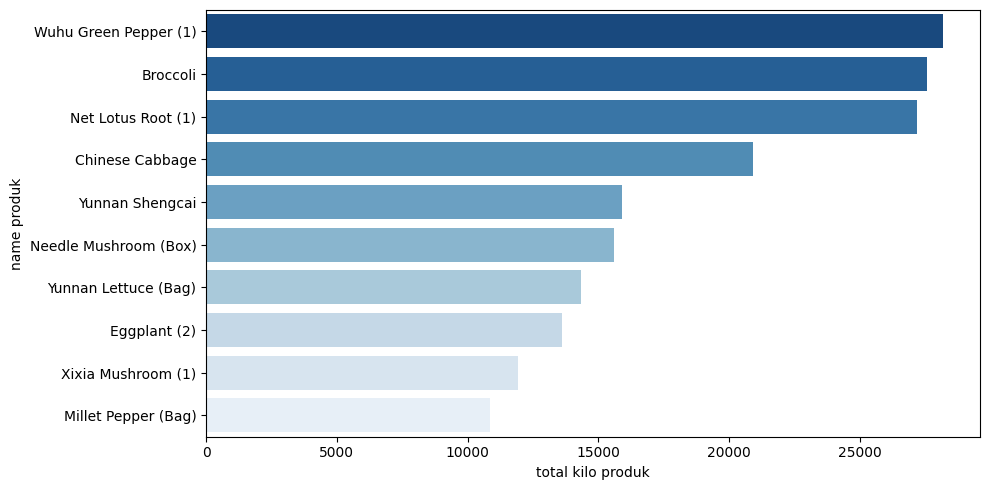

In [25]:
plt.figure(figsize = (10, 5))
top_items = (
    df_clean.groupby('Item Name')['Quantity Sold (kilo)'].sum().nlargest(10).reset_index()
)

sns.barplot(data = top_items, x = 'Quantity Sold (kilo)', y='Item Name', palette='Blues_r')
plt.xlabel("total kilo produk")
plt.ylabel('name produk')
plt.tight_layout()



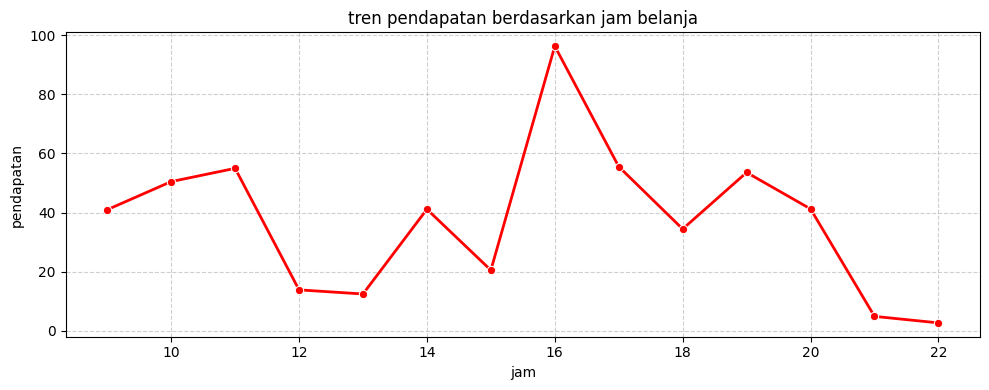

In [28]:
plt.figure(figsize = (10, 4))
hourly_sales = df_clean.groupby('Hour')['Total Revenue'].sum().reset_index()
sns.lineplot(data=hourly_sales, x = 'Hour', y= 'Total Revenue', marker= 'o', color = 'red', linewidth = 2)

plt.title('tren pendapatan berdasarkan jam belanja')
plt.xlabel('jam')
plt.ylabel('pendapatan')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

#korelasi harga dan kuantitas

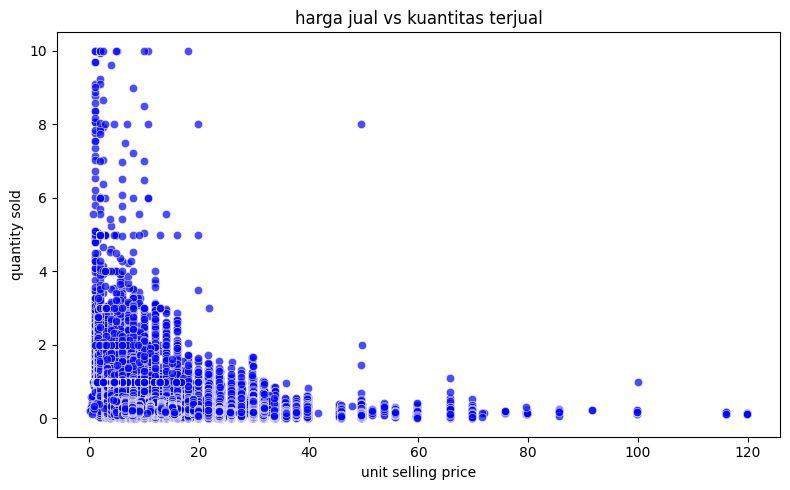

In [30]:
plt.figure(figsize = (8, 5))
data_scatter = df_clean[df_clean['Quantity Sold (kilo)'] <= 10]

sns.scatterplot(
    data = data_scatter,
    x = 'Unit Selling Price (RMB/kg)',
    y = 'Quantity Sold (kilo)',
    alpha = 0.7,
    color = 'blue'
)
plt.title('harga jual vs kuantitas terjual')
plt.xlabel('unit selling price')
plt.ylabel('quantity sold')
plt.tight_layout()
plt.show()

#keuntungan

In [35]:
df_clean['Date'] = pd.to_datetime(df_clean['Date']).dt.strftime('%Y-%m-%d')
data3['Date'] = pd.to_datetime(data3['Date']).dt.strftime('%Y-%m-%d')

In [36]:
df_profit = pd.merge(
    df_clean, data3, on = ['Date', 'Item Code'], how = 'left'
)

In [48]:
df_profit['Total Cost']=(
    df_profit['Wholesale Price (RMB/kg)'] * df_profit['Quantity Sold (kilo)']
)
df_profit['Profit'] = df_profit['Total Revenue'] - df_profit['Total Cost']
df_profit['Profit Margin (%)'] = (
    df_profit['Profit'] / df_profit['Total Revenue']
) * 100

/tmp/ipykernel_4348/488702120.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


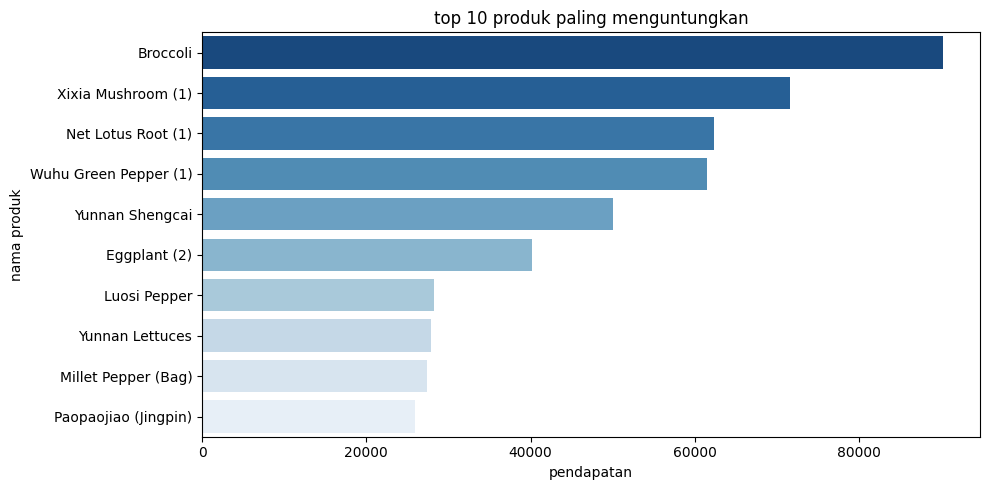

In [50]:
top_profit_items = (
    df_profit.groupby('Item Name')['Profit'].sum().nlargest(10).reset_index()
)

plt.figure(figsize = (10, 5))
sns.barplot(
    data = top_profit_items,
    x = 'Profit',
    y = 'Item Name',
    palette = 'Blues_r'
)
plt.title('top 10 produk paling menguntungkan')
plt.xlabel('pendapatan')
plt.ylabel('nama produk')
plt.tight_layout()
plt.show()

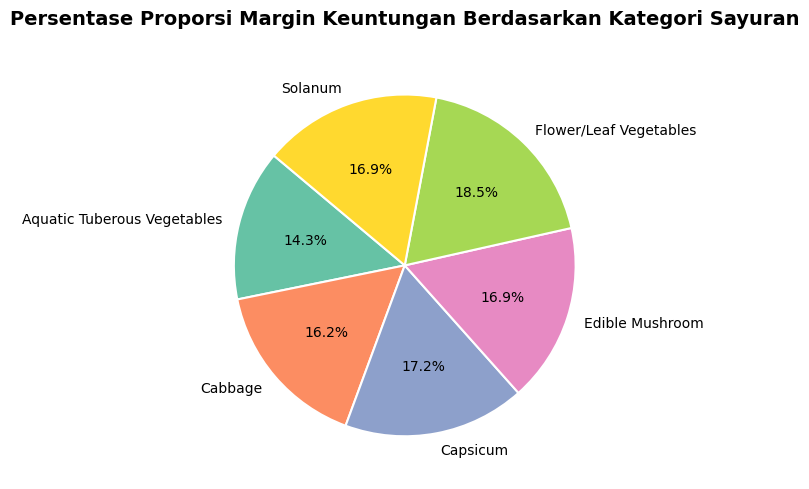

In [56]:
category_profit = (
    df_profit.groupby('Category Name')[['Total Revenue', 'Total Cost', 'Profit']]
    .sum()
    .reset_index()
)
category_profit['Margin (%)']= (
    category_profit['Profit'] / category_profit['Total Revenue']
) * 100

plt.figure(figsize= (10, 5))
plt.pie(
    category_profit['Margin (%)'],
    labels=category_profit['Category Name'],
    autopct='%1.1f%%',
    startangle=140,
    colors=sns.color_palette('Set2'),
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5},
)
plt.title(
    'Persentase Proporsi Margin Keuntungan Berdasarkan Kategori Sayuran',
    fontsize=14,
    fontweight='bold',
    pad=20,
)
plt.tight_layout()
plt.show()

#kerugian akibat pembusukan

In [59]:
df_loss = pd.merge(df_profit, data4[['Item Code', 'Loss Rate (%)']], on='Item Code', how='left')
df_loss

,Item Code,Item Name,Category Code,Category Name,Date,Time,Quantity Sold (kilo),Unit Selling Price (RMB/kg),Sale or Return,Discount (Yes/No),Total Revenue,Month,Day_of_Week,Hour,Wholesale Price (RMB/kg),Total Cost,Peofit,Profit Margin (%),Profit,Loss Rate (%)
0,102900005115168,Niushou Shengcai,1011010101,Flower/Leaf Vegetables,2020-10-30,10:02:13.748,0.743,5.0,sale,No,3.715,10,Friday,NaN,3.00,2.229,1.486,40.000000,1.486,4.39
1,102900005115168,Niushou Shengcai,1011010101,Flower/Leaf Vegetables,2020-10-30,10:48:42.707,0.502,5.0,sale,No,2.510,10,Friday,NaN,3.00,1.506,1.004,40.000000,1.004,4.39
2,102900005115168,Niushou Shengcai,1011010101,Flower/Leaf Vegetables,2020-10-30,11:10:13.023,0.301,5.0,sale,No,1.505,10,Friday,NaN,3.00,0.903,0.602,40.000000,0.602,4.39
3,102900005115168,Niushou Shengcai,1011010101,Flower/Leaf Vegetables,2020-10-30,12:34:32.084,0.382,5.0,sale,No,1.910,10,Friday,NaN,3.00,1.146,0.764,40.000000,0.764,4.39
4,102900005115168,Niushou Shengcai,1011010101,Flower/Leaf Vegetables,2020-10-30,13:33:59.748,0.261,5.0,sale,No,1.305,10,Friday,NaN,3.00,0.783,0.522,40.000000,0.522,4.39
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
878037,106973990980123,Hfyg Haixian Mushroom (Bunch),1011010801,Edible Mushroom,2022-07-28,20:26:46.053,1.000,1.5,sale,Yes,1.500,7,Thursday,NaN,2.02,2.020,-0.520,-34.666667,-0.520,0.12
878038,106973990980123,Hfyg Haixian Mushroom (Bunch),1011010801,Edible Mushroom,2022-07-28,20:47:51.842,1.000,2.5,sale,No,2.500,7,Thursday,NaN,2.02,2.020,0.480,19.200000,0.480,0.12
878039,106973990980123,Hfyg Haixian Mushroom (Bunch),1011010801,Edible Mushroom,2022-07-28,20:48:23.670,1.000,1.5,sale,Yes,1.500,7,Thursday,NaN,2.02,2.020,-0.520,-34.666667,-0.520,0.12
878040,106973990980123,Hfyg Haixian Mushroom (Bunch),1011010801,Edible Mushroom,2022-07-29,18:42:16.217,1.000,2.5,sale,No,2.500,7,Friday,NaN,2.03,2.030,0.470,18.800000,0.470,0.12


In [60]:
df_loss['Loss Quantity (kilo)'] = df_loss['Quantity Sold (kilo)'] * (df_loss['Loss Rate (%)'] / 100)
df_loss['Loss Value (RMB)'] = df_loss['Loss Quantity (kilo)'] * df_loss['Wholesale Price (RMB/kg)']

/tmp/ipykernel_4348/3903138445.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_loss_rate, x='Loss Rate (%)', y='Item Name', palette='Blues_r')


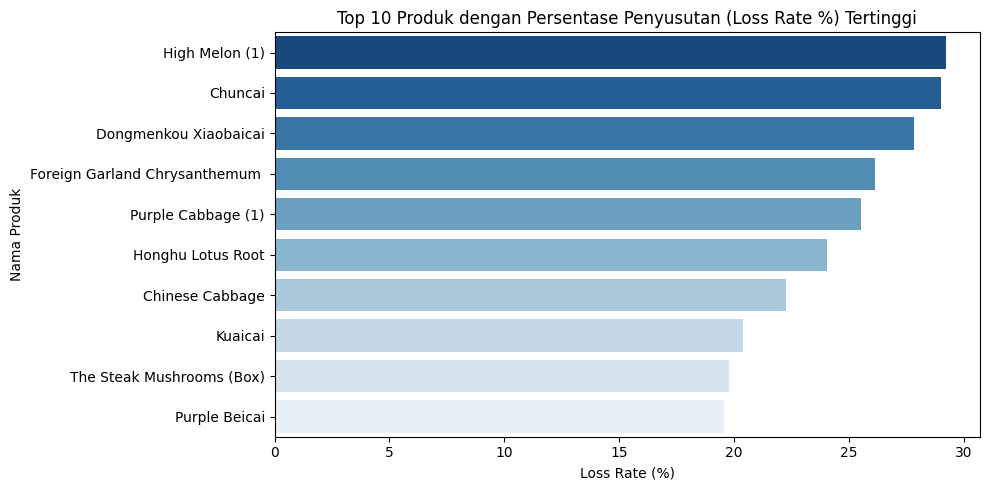

In [63]:
top_loss_rate = data4.sort_values(by='Loss Rate (%)', ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(data=top_loss_rate, x='Loss Rate (%)', y='Item Name', palette='Blues_r')
plt.title('Top 10 Produk dengan Persentase Penyusutan (Loss Rate %) Tertinggi')
plt.xlabel('Loss Rate (%)')
plt.ylabel('Nama Produk')
plt.tight_layout()
plt.show()